# 2026-10-17 NSF [S II] doublet follow-up tests

Follow the final exchange in [Testing NSF Components](https://chatgpt.com/c/6ad09a2e-b224-83ec-af20-b3ec9a0bf01b).
This is a new, self-contained notebook derived from `20261016_check_six_NSF_diagnostics_by_stage.ipynb`; the recorded source SHA256 is the snapshot at creation, before the later plot update.

1. Test the corrected **linear** [S II]6716/6731 ratio versus EW(Halpha) for NSF at **log Sigma_star > 8.5** (M_sun kpc^-2). Compare stages within common EW bins, with an all-stellar-density comparison and additional joint mass/EW cells.
2. Test ratio versus projected distance to the nearest selected **SF spaxel with EW(Halpha) > 20 Angstrom** in the observed product. This is a proximity proxy, not a segmented H II-region catalogue or a deprojected distance.
3. Test ratio versus intrinsic Halpha dispersion, on paired finite pixels.

The working hypothesis is a changing contribution of young-star-associated NSF emission. These observational comparisons cannot identify ionising sources, demonstrate ram-pressure causation, or distinguish mixture changes from all other gas changes. A residual stage difference at fixed EW can also reflect unmatched mass, radius, galaxy properties, selection, or measurement errors. A null contrast is not evidence of equivalence.

## Material Passport
Type: exploratory observational analysis; source: local MAUVE products; unit of resampling: whole product/galaxy (NGC4567_8 remains one cluster); status: results determined by execution below.

Inherited: geometry, inclinations <80 degrees, masks, Balmer-detected NSF definition, stellar SNR_POSTFIT >25, corrected sulfur fluxes and each sulfur line's raw detection gate. Product `SII6730` is displayed as conventional 6731. No TNSF branch, density inversion, ratio clipping, or fit-product writes.

New support, explicitly adapted to the new axes: each galaxy/bin needs >=50 usable pixels, >=20 paired NSF measurements, and >=25 distinct nonnegative gas bins; stage estimates need >=5 supported galaxies. New bins use their own paired measurements rather than borrowing support from a different axis. The reference mass profile uses paired ratio/dispersion support and can therefore differ slightly from the source shared-support profile.

Central estimate: arithmetic mean of per-galaxy medians. Bands: 16th--84th percentile whole-galaxy bootstrap (10,000 draws), with unsupported galaxies retained as missing in stage resampling. Supported estimates and bands require >=90% of draws to be finite; below-threshold descriptive points do not require a bootstrap interval. Per-bin contrasts use the same within-stage draws across bins; between-stage draws are independent. These are exploratory pointwise intervals, not simultaneous significance tests.

Keep measured ratios near or beyond the low-density asymptote: no universal hard ratio cutoff, density floor, or numerical electron density is imposed. PSF, spectral-fit bins, line errors, selection and saturation limit the interpretation. Fit-window header values are printed; do not assume that absent LMIN/LMAX proves a 7000-Angstrom rerun.


Plot update (2026-10-17): retain the existing **>=5** galaxy threshold.
Bins below that threshold are shown as descriptive points when at least one
galaxy passes the original per-galaxy measurement/support requirements.
Solid segments join two fully supported bins; any adjacent segment touching a
low-count bin is dashed. Low-count points are open circles (including isolated
points). Missing measurements remain gaps. Low-count bins have no shaded
bootstrap band and remain excluded from supported stage inference/contrasts.


In [1]:
from __future__ import annotations

import math
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
DATA_ROOT = PROJECT_ROOT / "v3tk_v7.6.8"
CATALOG_PATH = PROJECT_ROOT / "mauve_master_wiki_newclass.fits"
GEOMETRY_PATH = PROJECT_ROOT / "MAUVE_effective_radii.csv"

MASS_FILE_PATTERN = "{galid}_spatial_binning_maps_further.fits"
SFR_FILE_PATTERNS = (
    "{galid}_gas_bin_maps_further.fits",
    "{galid}_gas_BIN_maps_further.fits",
)
EW_FILE_PATTERNS = (
    "{galid}_proxy_EW_maps_further.fits",
    "{galid}_proxy_EW_maps.fits",
)
MASK_FILE_PATTERN = "{galid}_mask.fits"
SFH_FILE_PATTERN = "{galid}_sfh_maps.fits"

MASS_HDU = "LOGMASS_SURFACE_DENSITY"
BIN_HDU_MASS = "BINID"
BIN_HDU_GAS = "BIN_ID"
SFR_HDU = "LOGSFR_SURFACE_DENSITY_HII"
# All-spaxel ordinate only; SFR_HDU remains the original SF-selection map.
ALL_SFR_HDU = "LOGSFR_SURFACE_DENSITY"
EW_HDU = "PROXY_EWHA"
HALPHA_SIGMA_OBS_HDU = "HA6562_SIGMA"
HALPHA_SIGMA_CORR_HDU = "HA6562_SIGMA_CORR"
MASK_TABLE_HDU = "MASKFILE"
MASK_COLUMN = "MASK"
SFH_SNR_POSTFIT_HDU = "SNR_POSTFIT"

EW_HA_MIN = 6.0
# Distance references only; the inherited SF/NSF classification stays at EW > 6.
SF_REFERENCE_EW_HA_MIN = 20.0
HALPHA_SIGMA_MAX = 45.0
SFH_SNR_POSTFIT_MIN = 25.0
I_MAX_PRIMARY = 80.0
MIN_VALID_PIXELS_PER_BIN = 50
MIN_SF_PIXELS_PER_BIN = 20
WCS_TOLERANCE_ARCSEC = 0.05

SIGMA_BIN_WIDTH = 0.25
RADIUS_BIN_WIDTH = 0.25
FIXED_RELIABLE_RANGES = {"log_sigma_star": (7.0, 9.5), "radius_re": (0.0, 2.5)}
MASS_CONTOUR_LEVEL = 7.5

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.grid": False,
})


BALMER_LINES = ("HB4861", "HA6562")
REASON_LABELS = (
    "BPT: stable non-HII", "BPT: weak/ambiguous/unavailable", "HII SFR unavailable",
    "EW unavailable", "EW <= 6", "Dispersion unavailable", "Dispersion >= 45",
)
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
DIAGNOSTIC_MIN_PIXELS_PER_BIN = 20
MIN_DISTINCT_GAS_BINS_PER_BIN = 25
MIN_GALAXIES_PER_STAGE_BIN = 5
DISPERSION_YLIM = (0.0, 120.0)
CATEGORY_ORDER = ("NSF",)
VARIABLES = ("log_sigma_star", "radius_re")
BRANCH_LABELS = {"equal": "Equal-galaxy mean of galaxy medians", "pooled": "Pooled-spaxel median"}
STAGE_COLORS = {"pre-peak": "#2166ac", "close-to-peak": "#1a9850", "post-peak": "#d73027"}
print(f"Project root: {PROJECT_ROOT}")
print("Scope: NSF sulfur-doublet follow-up; equal-galaxy mean of medians")



SOURCE_SHA256 = '81d686679b24c299e244034ad903124e244424f7dadbe2fdad8d9dea96514f27'

from scipy.spatial import cKDTree
HIGH_MASS_CUT = 8.5
MIN_FINITE_BOOTSTRAP_FRACTION = 0.90
EW_EDGES = np.array([0., 1., 2., 3., 4., 6., 10., 20., 40., 80., np.inf])
DISTANCE_EDGES = np.array([0., .1, .25, .5, 1., 2., 4., 8., np.inf])
DISPERSION_EDGES = np.array([0., 20., 30., 40., 50., 60., 80., 120., np.inf])
MASS_EDGES = np.arange(6., 11.51, .25)
JOINT_MASS_EDGES = np.array([8.5, 9., 9.5, 10., np.inf])


Project root: /Users/Igniz/Desktop/ICRAR/further
Scope: NSF sulfur-doublet follow-up; equal-galaxy mean of medians


## Inherited live-product discovery, geometry and NSF classification
The following helpers and QC pass come from the source notebook. Maps are loaded one product at a time.

In [2]:
def normalise_stage_label(value) -> str:
    mapping = {
        1: "pre-peak", 1.0: "pre-peak", "1": "pre-peak",
        2: "close-to-peak", 2.0: "close-to-peak", "2": "close-to-peak",
        3: "post-peak", 3.0: "post-peak", "3": "post-peak",
        "prepeak": "pre-peak", "pre-peak": "pre-peak",
        "close-to-peak": "close-to-peak", "closetopeak": "close-to-peak",
        "near-peak": "close-to-peak", "postpeak": "post-peak", "post-peak": "post-peak",
    }
    key = value if isinstance(value, (int, float)) else str(value).strip().lower().replace(" ", "")
    if key not in mapping:
        raise ValueError(f"Unrecognised RPS/infall stage label: {value!r}")
    return mapping[key]

def first_existing(paths):
    for path in paths:
        for candidate in (path, Path(str(path) + ".gz")):
            if candidate.exists():
                return candidate
    return None

def load_fits_map(path: Path, hdu_name: str, *, return_header: bool = False):
    with fits.open(path, memmap=True) as hdul:
        names = {hdu.name.upper() for hdu in hdul}
        if hdu_name.upper() not in names:
            raise KeyError(f"{path}: missing HDU {hdu_name}; available={sorted(names)}")
        hdu = hdul[hdu_name]
        data = np.asarray(hdu.data, dtype=float).copy()
        header = hdu.header.copy()
    return (data, header) if return_header else data

def load_ngist_mask(path: Path, shape):
    with fits.open(path, memmap=True) as hdul:
        if MASK_TABLE_HDU not in hdul:
            raise KeyError(f"{path}: missing table HDU {MASK_TABLE_HDU}")
        table = hdul[MASK_TABLE_HDU].data
        if MASK_COLUMN not in table.names:
            raise KeyError(f"{path}: missing mask column {MASK_COLUMN}; available={table.names}")
        flat = np.asarray(table[MASK_COLUMN], dtype=int)
    if flat.size != int(np.prod(shape)):
        raise ValueError(f"{path}: mask length {flat.size} cannot reshape to {shape}")
    return flat.reshape(shape)

def celestial_wcs_separation_arcsec(header_a, header_b, shape):
    wa, wb = WCS(header_a).celestial, WCS(header_b).celestial
    if not wa.has_celestial or not wb.has_celestial:
        return np.inf
    ny, nx = shape
    x = np.array([0, nx - 1, 0, nx - 1, (nx - 1) / 2])
    y = np.array([0, 0, ny - 1, ny - 1, (ny - 1) / 2])
    raa, deca = wa.pixel_to_world_values(x, y)
    rab, decb = wb.pixel_to_world_values(x, y)
    cosd = np.cos(np.deg2rad((deca + decb) / 2))
    return float(np.nanmax(np.hypot((raa - rab) * cosd, deca - decb)) * 3600.0)

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    # Minimum elliptical R/Re over the physical components of one product.
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, component in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(
            ra, dec, component.center_ra_deg, component.center_dec_deg
        )
        pa = np.deg2rad(float(component.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        component_radius = np.sqrt(
            (major / float(component.a_re_arcsec)) ** 2
            + (minor / float(component.b_re_arcsec)) ** 2
        )
        radius = np.minimum(radius, component_radius)
    radius[~np.isfinite(radius)] = np.nan
    return radius

def intrinsic_sigma_from_maps(sigma_obs, sigma_corr):
    sigma2 = np.asarray(sigma_obs, dtype=float) ** 2 - np.asarray(sigma_corr, dtype=float) ** 2
    result = np.full(sigma2.shape, np.nan, dtype=float)
    valid = np.isfinite(sigma2) & (sigma2 > 0)
    result[valid] = np.sqrt(sigma2[valid])
    return result

def load_galaxy_maps(row, geometry):
    mass, mass_header = load_fits_map(row.mass_path, MASS_HDU, return_header=True)
    mass_bin = load_fits_map(row.mass_path, BIN_HDU_MASS)
    gas_bin, gas_header = load_fits_map(row.sfr_path, BIN_HDU_GAS, return_header=True)
    sfr = load_fits_map(row.sfr_path, SFR_HDU)
    ew_ha = load_fits_map(row.ew_path, EW_HDU)
    sigma_obs = load_fits_map(row.sfr_path, HALPHA_SIGMA_OBS_HDU)
    sigma_corr = load_fits_map(row.sfr_path, HALPHA_SIGMA_CORR_HDU)
    snr_postfit = load_fits_map(row.sfh_path, SFH_SNR_POSTFIT_HDU)
    shapes = {a.shape for a in (
        mass, mass_bin, gas_bin, sfr, ew_ha, sigma_obs, sigma_corr, snr_postfit
    )}
    if len(shapes) != 1:
        raise ValueError(f"{row.GALID}: map shape mismatch {sorted(shapes)}")
    wcs_sep = celestial_wcs_separation_arcsec(mass_header, gas_header, mass.shape)
    if not np.isfinite(wcs_sep) or wcs_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f"{row.GALID}: mass/gas WCS mismatch {wcs_sep:.4f} arcsec")
    ngist_mask = load_ngist_mask(row.mask_path, mass.shape)
    components = geometry.loc[geometry.notebook_product_id.eq(row.GALID)].copy()
    radius_re = calculate_deprojected_radius(mass.shape, mass_header, components)
    sigma_intrinsic = intrinsic_sigma_from_maps(sigma_obs, sigma_corr)
    valid = (
        np.isfinite(mass) & np.isfinite(gas_bin) & (ngist_mask == 0) & np.isfinite(radius_re)
    )
    sf = (
        valid & np.isfinite(sfr) & np.isfinite(ew_ha) & (ew_ha > EW_HA_MIN)
        & np.isfinite(sigma_intrinsic) & (sigma_intrinsic < HALPHA_SIGMA_MAX)
    )
    maps = {
        "log_sigma_star": mass,
        "log_sigma_sfr": sfr,
        "radius_re": radius_re,
        "snr_postfit": snr_postfit,
        "sigma_intrinsic": sigma_intrinsic,
        "gas_bin_id": gas_bin,
        "ew_ha": ew_ha,
        "valid_disc_mask": valid,
        "sf_mask": sf,
        "mass_header": mass_header,
        "wcs_separation_arcsec": wcs_sep,
    }
    return add_detection_categories(maps, row, ew_ha, sigma_intrinsic)

def add_detection_categories(maps, row, ew_ha, sigma_intrinsic):
    """Use Balmer-only ND and preserve the original SF selection exactly."""
    valid, sf = maps["valid_disc_mask"], maps["sf_mask"]
    detected = {}
    invalid_any = np.zeros(valid.shape, dtype=bool)
    with fits.open(row.sfr_path, memmap=True) as hdul:
        header = hdul[0].header
        sn_cut, flux_floor = float(header["CUT_SN"]), float(header["NOISE"])
        if not (np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(flux_floor) and flux_floor > 0):
            raise ValueError(f"{row.GALID}: invalid detection thresholds")
        if str(header["BPTMODE"]).strip().lower() != "both":
            raise ValueError(f"{row.GALID}: expected the original both-BPT selection")
        for line in BALMER_LINES:
            flux = np.asarray(hdul[line + "_FLUX"].data, dtype=float)
            error = np.asarray(hdul[line + "_FLUX_ERR"].data, dtype=float)
            if flux.shape != valid.shape or error.shape != valid.shape:
                raise ValueError(f"{row.GALID}: {line} shape mismatch")
            measurable = np.isfinite(flux) & np.isfinite(error) & (error > 0)
            invalid_any |= ~measurable
            with np.errstate(divide="ignore", invalid="ignore"):
                detected[line] = measurable & (flux / error >= sn_cut) & (flux >= flux_floor)
        # Do not use the old NII_HA_BPT / SII_HA_BPT ratio HDUs as class maps.
        nii = np.asarray(hdul["NII_BPT"].data).copy()
        sii = np.asarray(hdul["SII_BPT"].data).copy()
        for name, arr in (("NII_BPT", nii), ("SII_BPT", sii)):
            if arr.shape != valid.shape or not np.isin(arr[valid], [-1, 0, 1, 2, 3]).all():
                raise ValueError(f"{row.GALID}: invalid {name} class map")
        provenance = {key: header.get(key, "not recorded")
                      for key in ("CUT_SN", "NOISE", "BPTMODE", "BPTLIMIT", "DUSTLAW")}
    balmer_detected = detected["HA6562"] & detected["HB4861"]
    if np.any(sf & ~balmer_detected):
        raise AssertionError(f"{row.GALID}: original SF includes a Balmer non-detection")
    nd = valid & ~balmer_detected
    nsf = valid & balmer_detected & ~sf
    # Exclusive bookkeeping, in this order: HII gate -> EW gate -> sigma gate.
    # This is a first-failed-gate decomposition, not a unique physical cause.
    has_sfr = np.isfinite(maps["log_sigma_sfr"])
    stable_non_hii = np.isin(nii, [2, 3]) | np.isin(sii, [2, 3])
    both_hii = (nii == 1) & (sii == 1)
    conditions = (
        ~has_sfr & stable_non_hii,
        ~has_sfr & ~both_hii,
        ~has_sfr,
        ~np.isfinite(ew_ha),
        ew_ha <= EW_HA_MIN,
        ~np.isfinite(sigma_intrinsic),
        sigma_intrinsic >= HALPHA_SIGMA_MAX,
    )
    remainder = nsf.copy()
    reasons = {}
    for label, condition in zip(REASON_LABELS, conditions):
        reasons[label] = remainder & condition
        remainder &= ~condition
    if remainder.any():
        raise AssertionError(f"{row.GALID}: unexplained detected non-SF pixels")
    category_sum = sf.astype(np.int8) + nd + nsf
    assert np.array_equal(category_sum, valid.astype(np.int8))
    assert np.array_equal(np.sum(list(reasons.values()), axis=0), nsf.astype(int))
    maps.update({
        "nii_bpt_class": nii, "sii_bpt_class": sii,
        "nd_mask": nd, "nsf_mask": nsf, "balmer_detected_mask": balmer_detected,
        "line_detected": detected, "nsf_reasons": reasons,
        "nd_invalid_mask": nd & invalid_any,
        "nd_measured_below_cut_mask": nd & ~invalid_any,
        "detection_provenance": provenance,
    })
    return maps

In [3]:
def read_master_catalogue(path):
    with fits.open(path) as hdul:
        table = hdul[1].data
        frame = pd.DataFrame({
            "galaxy": [str(value).strip() for value in table["Galaxy"]],
            "logMstar": np.asarray(table["logMstar"], dtype=float),
            "stage_code": np.asarray(table["class"], dtype=float),
        })
    frame["stage"] = frame.stage_code.map(normalise_stage_label)
    return frame


def discover_products(data_root):
    rows = []
    for folder in sorted(path for path in data_root.iterdir()
                         if path.is_dir() and not path.name.endswith("_logs")):
        galid = folder.name
        rows.append({
            "GALID": galid,
            "mass_path": first_existing([folder / MASS_FILE_PATTERN.format(galid=galid)]),
            "sfr_path": first_existing([
                folder / pattern.format(galid=galid) for pattern in SFR_FILE_PATTERNS
            ]),
            "ew_path": first_existing([
                folder / pattern.format(galid=galid) for pattern in EW_FILE_PATTERNS
            ]),
            "mask_path": first_existing([folder / MASK_FILE_PATTERN.format(galid=galid)]),
            "sfh_path": first_existing([
                folder / SFH_FILE_PATTERN.format(galid=galid)
            ]),
        })
    return pd.DataFrame(rows)


STAGE_ORDER = ("pre-peak", "close-to-peak", "post-peak")
PANEL_ORDER = STAGE_ORDER + ("all stages",)
STAGE_LABELS = {
    "pre-peak": "Pre-peak",
    "close-to-peak": "Close-to-peak",
    "post-peak": "Post-peak",
    "all stages": "All stages",
}

master = read_master_catalogue(CATALOG_PATH)
geometry = pd.read_csv(GEOMETRY_PATH)
required_geometry = {
    "galaxy", "notebook_product_id", "mauve_infall_stage", "center_ra_deg",
    "center_dec_deg", "inclination_deg", "pa_deg_east_of_north",
    "a_re_arcsec", "b_re_arcsec",
}
missing_geometry = required_geometry - set(geometry.columns)
if missing_geometry:
    raise KeyError(f"{GEOMETRY_PATH}: missing columns {sorted(missing_geometry)}")

geometry = geometry.merge(
    master[["galaxy", "logMstar", "stage"]], on="galaxy", how="left",
    validate="one_to_one",
)
geometry["stage_from_geometry"] = geometry.mauve_infall_stage.map(normalise_stage_label)
if not geometry.stage.eq(geometry.stage_from_geometry).all():
    raise RuntimeError("Stage disagreement between the master and effective-radius catalogues")

product_meta = []
for galid, group in geometry.groupby("notebook_product_id", sort=False):
    if group.stage.nunique() != 1:
        raise RuntimeError(f"{galid}: physical components have inconsistent stages")
    product_meta.append({
        "GALID": galid,
        "components": ",".join(group.galaxy),
        "stage": group.stage.iloc[0],
        "inclination": float(group.inclination_deg.max()),
    })

inventory = pd.DataFrame(product_meta).merge(
    discover_products(DATA_ROOT), on="GALID", how="left", validate="one_to_one"
)
candidates = inventory.loc[
    inventory.stage.isin(STAGE_ORDER) & inventory.inclination.lt(I_MAX_PRIMARY)
].sort_values(["stage", "GALID"]).reset_index(drop=True)

# This first pass performs full live QC and records only range/count summaries.
# Maps are not cached so the combined notebook does not retain all galaxies in memory.
qc_rows = []
for row in candidates.itertuples(index=False):
    flags = []
    for label, path in (("mass", row.mass_path), ("sfr", row.sfr_path),
                        ("ew", row.ew_path), ("mask", row.mask_path),
                        ("sfh", row.sfh_path)):
        if not isinstance(path, Path) or not path.exists():
            flags.append(f"missing_{label}_product")
    maps = None
    if not flags:
        try:
            maps = load_galaxy_maps(row, geometry)
            valid = maps["valid_disc_mask"]
            if np.any(maps["sf_mask"] & ~valid):
                flags.append("sf_not_subset_of_valid")
        except Exception as exc:
            flags.append(f"load_error:{type(exc).__name__}:{exc}")
    if maps is not None and not flags:
        valid = maps["valid_disc_mask"]
        category_total = (
            maps["sf_mask"].astype(np.int8)
            + maps["nd_mask"].astype(np.int8)
            + maps["nsf_mask"].astype(np.int8)
        )
        if not np.array_equal(category_total, valid.astype(np.int8)):
            flags.append("category_accounting_failure")
    qc_rows.append({
        "GALID": row.GALID,
        "components": row.components,
        "stage": row.stage,
        "inclination_deg": row.inclination,
        "N_valid": int(valid.sum()) if maps is not None and not flags else 0,
        "N_NSF": int(maps["nsf_mask"].sum()) if maps is not None and not flags else 0,
        "sigma_min": float(np.nanmin(maps["log_sigma_star"][valid]))
                     if maps is not None and not flags else np.nan,
        "sigma_max": float(np.nanmax(maps["log_sigma_star"][valid]))
                     if maps is not None and not flags else np.nan,
        "radius_min": float(np.nanmin(maps["radius_re"][valid]))
                      if maps is not None and not flags else np.nan,
        "radius_max": float(np.nanmax(maps["radius_re"][valid]))
                      if maps is not None and not flags else np.nan,
        "wcs_separation_arcsec": maps["wcs_separation_arcsec"]
                                if maps is not None and not flags else np.nan,
        "QC_flag": ";".join(flags) if flags else "OK",
    })
    del maps

SAMPLE_QC = pd.DataFrame(qc_rows)
passed_ids = set(SAMPLE_QC.loc[SAMPLE_QC.QC_flag.eq("OK"), "GALID"])
sample = candidates.loc[candidates.GALID.isin(passed_ids)].copy()

display(SAMPLE_QC)
display(SAMPLE_QC.groupby(["stage", "QC_flag"], observed=True).size().rename("N_galaxies"))
for stage in STAGE_ORDER:
    n_pass = int(sample.stage.eq(stage).sum())
    n_candidate = int(candidates.stage.eq(stage).sum())
    print(f"{STAGE_LABELS[stage]}: {n_pass}/{n_candidate} products pass QC")
    if n_pass == 0:
        raise RuntimeError(f"No {stage} galaxies passed the live product QC")
print(f"Total passing products: {len(sample)}/{len(candidates)}")

Pre-peak: 8/8 products pass QC
Close-to-peak: 5/5 products pass QC
Post-peak: 13/16 products pass QC
Total passing products: 26/29


,GALID,components,stage,inclination_deg,N_valid,N_NSF,sigma_min,sigma_max,radius_min,radius_max,wcs_separation_arcsec,QC_flag
0,NGC4298,NGC4298,close-to-peak,52.0,498540,44039,6.476232,9.372817,0.002597,2.927309,0.0,OK
1,NGC4424,NGC4424,close-to-peak,61.0,172561,38973,7.113861,9.027295,0.002721,2.533259,0.0,OK
2,NGC4501,NGC4501,close-to-peak,65.0,664236,263460,6.926827,10.916401,0.002436,2.862775,0.0,OK
3,NGC4654,NGC4654,close-to-peak,61.0,659231,124396,6.043689,9.750619,0.000637,2.836630,0.0,OK
4,NGC4694,NGC4694,close-to-peak,62.0,94538,28161,6.934593,9.479634,0.004544,3.796772,0.0,OK
5,IC3392,IC3392,post-peak,68.0,94575,9195,6.969276,9.253759,0.004326,3.084733,0.0,OK
6,NGC4064,NGC4064,post-peak,70.0,179882,34479,6.811374,9.428892,0.002945,1.939061,0.0,OK
7,NGC4293,NGC4293,post-peak,67.0,261523,63907,7.243091,10.336573,0.001645,1.842599,0.0,OK
8,NGC4380,NGC4380,post-peak,61.0,502065,53815,6.694095,10.141226,0.001755,2.963534,0.0,OK
9,NGC4394,NGC4394,post-peak,32.0,180654,46546,7.352380,10.783341,0.001999,1.488715,0.0,OK


stage          QC_flag                                                                                             
close-to-peak  OK                                                                                                       5
post-peak      OK                                                                                                      13
               missing_mass_product;missing_sfr_product;missing_ew_product;missing_mask_product;missing_sfh_product     3
pre-peak       OK                                                                                                       8
Name: N_galaxies, dtype: int64

## Paired ratio measurements and nearest-SF distance
SF reference pixels use the inherited SF definition, strict EW(Halpha) > 20 Angstrom, and stellar-continuum quality cut over the entire valid field, including outside the high-mass target selection. No SF reference gives missing distances, never a fabricated large distance. Distances are projected on-sky separations using celestial WCS and the gas-product DIST_MPC header. Field edges, masks, resolution and unobserved SF can bias this proxy. Negative EW is retained in QC and excluded only from the positive-emission EW profiles. All other finite-ratio analyses retain such pixels.
The stricter EW cut applies only to references; target NSF membership is unchanged. This selects a higher-EW H II-region proxy, not confirmed pure H II regions.


In [4]:
def selected_sf_reference_mask(maps):
    """High-EW subset of selected SF; leave the SF/NSF classification intact."""
    return (maps['sf_mask'] & maps['valid_disc_mask']
            & np.isfinite(maps['snr_postfit'])
            & (maps['snr_postfit'] > SFH_SNR_POSTFIT_MIN)
            & np.isfinite(maps['ew_ha'])
            & (maps['ew_ha'] > SF_REFERENCE_EW_HA_MIN))

def unit_sky_vectors(header, mask):
    y, x = np.nonzero(mask)
    ra, dec = WCS(header).celestial.pixel_to_world_values(x, y)
    ra, dec = np.deg2rad(ra), np.deg2rad(dec)
    return np.column_stack((np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)))

def nearest_sf_distance(header, sf, target, distance_mpc):
    result = np.full(target.shape, np.nan)
    if not sf.any() or not target.any() or not np.isfinite(distance_mpc) or distance_mpc <= 0:
        return result
    reference = unit_sky_vectors(header, sf)
    queries = unit_sky_vectors(header, target)
    if not np.isfinite(reference).all() or not np.isfinite(queries).all():
        raise ValueError('Nonfinite WCS coordinates in SF proximity calculation')
    chord, _ = cKDTree(reference).query(queries)
    result[target] = 2*np.arcsin(np.clip(chord/2, 0, 1))*distance_mpc*1000
    return result

TEST_SPECS = {
    'mass_reference': ('log_sigma_star', MASS_EDGES, 'all'),
    'EW_high_mass': ('ew_ha', EW_EDGES, 'high'),
    'EW_all_mass': ('ew_ha', EW_EDGES, 'all'),
    'distance_high_mass': ('distance_kpc', DISTANCE_EDGES, 'high'),
    'distance_all_mass': ('distance_kpc', DISTANCE_EDGES, 'all'),
    'sigma_high_mass': ('sigma_intrinsic', DISPERSION_EDGES, 'high'),
    'sigma_all_mass': ('sigma_intrinsic', DISPERSION_EDGES, 'all'),
}
for j, (lo, hi) in enumerate(zip(JOINT_MASS_EDGES[:-1], JOINT_MASS_EDGES[1:])):
    TEST_SPECS[f'EW_joint_mass_{j}'] = ('ew_ha', EW_EDGES, (lo, hi))

def mass_selection(mass, selection):
    if selection == 'high': return mass > HIGH_MASS_CUT
    if selection == 'all': return np.isfinite(mass)
    lo, hi = selection
    return (mass > HIGH_MASS_CUT) & (mass >= lo) & (mass < hi)

rows, qc, provenance = [], [], []
for row in sample.itertuples(index=False):
    maps = load_galaxy_maps(row, geometry)
    keep = maps['valid_disc_mask'] & np.isfinite(maps['snr_postfit']) & (maps['snr_postfit'] > SFH_SNR_POSTFIT_MIN)
    nsf = maps['nsf_mask'] & keep
    sf = selected_sf_reference_mask(maps)
    assert not np.any(nsf & sf)
    with fits.open(row.sfr_path, memmap=True) as hdul:
        header = hdul[0].header.copy()
        gas_header = hdul[BIN_HDU_GAS].header.copy()
        distance_mpc = float(header.get('DIST_MPC', np.nan))
        fluxes, gates = [], []
        for line in ('SII6716', 'SII6730'):
            raw = np.asarray(hdul[line+'_FLUX'].data, dtype=float)
            err = np.asarray(hdul[line+'_FLUX_ERR'].data, dtype=float)
            corr = np.asarray(hdul[line+'_FLUX_CORR'].data, dtype=float).copy()
            assert raw.shape == err.shape == corr.shape == nsf.shape
            with np.errstate(divide='ignore', invalid='ignore'):
                ok = (np.isfinite(raw) & np.isfinite(err) & (err > 0)
                      & (raw/err >= float(header['CUT_SN'])) & (raw >= float(header['NOISE']))
                      & np.isfinite(corr) & (corr > 0))
            fluxes.append(corr)
            gates.append(ok)
    ratio = np.full(nsf.shape, np.nan)
    doublet_ok = gates[0] & gates[1]
    ratio[doublet_ok] = fluxes[0][doublet_ok]/fluxes[1][doublet_ok]
    target = nsf & np.isfinite(ratio)
    maps['distance_kpc'] = nearest_sf_distance(gas_header, sf, target, distance_mpc)
    high = maps['log_sigma_star'] > HIGH_MASS_CUT
    qc.append(dict(GALID=row.GALID, stage=row.stage, N_NSF=int(nsf.sum()),
        N_ratio=int(target.sum()), N_high_mass_ratio=int((target & high).sum()),
        N_SF_selected=int((maps['sf_mask'] & keep).sum()),
        N_SF_reference=int(sf.sum()), SF_reference_EW_min=SF_REFERENCE_EW_HA_MIN, N_distance=int(np.isfinite(maps['distance_kpc'][target]).sum()),
        N_negative_EW=int((target & (maps['ew_ha'] < 0)).sum()),
        N_ratio_above_1p5=int((target & (ratio > 1.5)).sum()),
        ratio_min=float(np.min(ratio[target])) if target.any() else np.nan,
        ratio_max=float(np.max(ratio[target])) if target.any() else np.nan))
    provenance.append(dict(GALID=row.GALID, DIST_MPC=distance_mpc,
        **{k: header.get(k, 'not recorded') for k in ('LMIN','LMAX','CUT_SN','NOISE','BPTMODE','DUSTLAW')}))
    for test, (variable, edges, selection) in TEST_SPECS.items():
        x = maps[variable]
        mass_keep = mass_selection(maps['log_sigma_star'], selection)
        for b, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            interval = mass_keep & np.isfinite(x) & (x >= lo) & (x < hi)
            paired = target & interval
            # Match the reference's finite-dispersion support for the mass view.
            if test == 'mass_reference': paired &= np.isfinite(maps['sigma_intrinsic'])
            ids = maps['gas_bin_id'][paired]
            assert np.isfinite(ids).all() and np.all(ids == np.floor(ids))
            n_bins = len(np.unique(ids[ids >= 0]))
            n = int(paired.sum())
            n_usable = int((keep & interval).sum())
            eligible = (n_usable >= MIN_VALID_PIXELS_PER_BIN and n >= DIAGNOSTIC_MIN_PIXELS_PER_BIN
                        and n_bins >= MIN_DISTINCT_GAS_BINS_PER_BIN)
            values = ratio[paired]
            rows.append(dict(test=test, variable=variable, GALID=row.GALID, stage=row.stage,
                bin=b, left=lo, right=hi, N_usable=n_usable, N_paired=n, N_gas_bins=n_bins,
                eligible=eligible, median=float(np.median(values)) if n else np.nan))
    print(f'{row.GALID}: {target.sum():,} finite-ratio NSF pixels; {sf.sum():,} SF reference pixels with EW(Halpha) > {SF_REFERENCE_EW_HA_MIN:g} Angstrom')
    del maps, ratio, fluxes, gates

GALAXY_BINS = pd.DataFrame(rows)
RATIO_QC = pd.DataFrame(qc)
PRODUCT_PROVENANCE = pd.DataFrame(provenance)
display(RATIO_QC)
display(PRODUCT_PROVENANCE)
display(RATIO_QC.groupby('stage')[['N_NSF','N_ratio','N_high_mass_ratio','N_SF_reference','N_distance']].sum())
print('Ratios above 1.5 are counted for QC and retained. This is not a universal physical cutoff.')


NGC4298: 34,685 finite-ratio NSF pixels; 43,309 SF reference pixels with EW(Halpha) > 20 Angstrom
NGC4424: 31,548 finite-ratio NSF pixels; 4,217 SF reference pixels with EW(Halpha) > 20 Angstrom
NGC4501: 252,538 finite-ratio NSF pixels; 78,476 SF reference pixels with EW(Halpha) > 20 Angstrom
NGC4654: 112,871 finite-ratio NSF pixels; 166,203 SF reference pixels with EW(Halpha) > 20 Angstrom
NGC4694: 26,310 finite-ratio NSF pixels; 337 SF reference pixels with EW(Halpha) > 20 Angstrom
IC3392: 6,512 finite-ratio NSF pixels; 3,576 SF reference pixels with EW(Halpha) > 20 Angstrom
NGC4064: 26,106 finite-ratio NSF pixels; 1,882 SF reference pixels with EW(Halpha) > 20 Angstrom
NGC4293: 35,773 finite-ratio NSF pixels; 154 SF reference pixels with EW(Halpha) > 20 Angstrom
NGC4380: 22,717 finite-ratio NSF pixels; 11,000 SF reference pixels with EW(Halpha) > 20 Angstrom
NGC4394: 18,417 finite-ratio NSF pixels; 6,296 SF reference pixels with EW(Halpha) > 20 Angstrom
NGC4405: 8,774 finite-ratio N

,GALID,stage,N_NSF,N_ratio,N_high_mass_ratio,N_SF_selected,N_SF_reference,SF_reference_EW_min,N_distance,N_negative_EW,N_ratio_above_1p5,ratio_min,ratio_max
0,NGC4298,close-to-peak,43104,34685,3418,138402,43309,20.0,34685,0,14601,0.755977,3.100549
1,NGC4424,close-to-peak,37811,31548,130,8994,4217,20.0,31548,0,10929,0.972593,2.674755
2,NGC4501,close-to-peak,261968,252538,80388,251607,78476,20.0,252538,0,95443,0.487071,3.683050
3,NGC4654,close-to-peak,117845,112871,4049,320781,166203,20.0,112871,0,35698,0.903067,2.036807
4,NGC4694,close-to-peak,28137,26310,6768,1058,337,20.0,26310,0,10311,0.567485,3.438066
5,IC3392,post-peak,9123,6512,151,13888,3576,20.0,6512,0,3097,0.707061,2.377208
6,NGC4064,post-peak,33921,26106,5132,3273,1882,20.0,26106,0,12311,0.549891,3.416594
7,NGC4293,post-peak,63400,35773,20527,471,154,20.0,35773,0,15703,0.457097,4.243113
8,NGC4380,post-peak,51190,22717,5793,56075,11000,20.0,22717,0,8082,0.594606,3.707617
9,NGC4394,post-peak,45294,18417,8902,30430,6296,20.0,18417,0,6813,0.458007,3.998422


,GALID,DIST_MPC,LMIN,LMAX,CUT_SN,NOISE,BPTMODE,DUSTLAW
0,NGC4298,16.5,not recorded,not recorded,3,20,both,calzetti
1,NGC4424,16.5,not recorded,not recorded,3,20,both,calzetti
2,NGC4501,16.5,not recorded,not recorded,3,20,both,calzetti
3,NGC4654,16.5,not recorded,not recorded,3,20,both,calzetti
4,NGC4694,16.5,not recorded,not recorded,3,20,both,calzetti
5,IC3392,16.5,not recorded,not recorded,3,20,both,calzetti
6,NGC4064,16.5,not recorded,not recorded,3,20,both,calzetti
7,NGC4293,16.5,not recorded,not recorded,3,20,both,calzetti
8,NGC4380,16.5,not recorded,not recorded,3,20,both,calzetti
9,NGC4394,16.5,not recorded,not recorded,3,20,both,calzetti


,N_NSF,N_ratio,N_high_mass_ratio,N_SF_reference,N_distance
stage,,,,,
close-to-peak,488865,457952,94753,292542,457952
post-peak,815887,602283,248339,61662,602283
pre-peak,929104,805528,96733,788098,805528


## Whole-galaxy bootstrap and fixed-bin stage contrasts
Unsupported inferential estimates remain missing; descriptive plot values retain below-threshold bins. Open-ended overflow bins appear in tables and are excluded from finite-axis plots. EW bins condition on an interval, not an exact value. Joint mass/EW tables provide a narrower mass comparison where support permits; they still do not match radius or other galaxy properties. Leave-one-galaxy-out ranges assess dependence on individual supported contributors; they are sensitivity summaries, not confidence intervals.

In [5]:

rng = np.random.default_rng(RANDOM_SEED)
STAGE_IDS = {stage: sample.loc[sample.stage.eq(stage), 'GALID'].tolist() for stage in STAGE_ORDER}
BOOT_INDICES = {stage: rng.integers(0, len(ids), size=(N_BOOTSTRAP, len(ids)))
                for stage, ids in STAGE_IDS.items()}

def bootstrap_mean_medians(values, indices):
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    central = float(values[finite].mean()) if finite.any() else np.nan
    sampled = values[indices]
    counts = np.isfinite(sampled).sum(axis=1)
    draws = np.divide(np.nansum(sampled, axis=1), counts,
                      out=np.full(len(indices), np.nan), where=counts > 0)
    return central, draws

profile_rows, BOOT_DRAWS = [], {}
for (test, stage), group in GALAXY_BINS.groupby(['test','stage'], sort=False):
    ids = STAGE_IDS[stage]
    for b, g in group.groupby('bin', sort=True):
        v = g.set_index('GALID').reindex(ids)
        values = v['median'].where(v.eligible).to_numpy()
        central, draws = bootstrap_mean_medians(values, BOOT_INDICES[stage])
        n = int(np.isfinite(values).sum())
        support = n >= MIN_GALAXIES_PER_STAGE_BIN
        if not support: draws[:] = np.nan
        finite = draws[np.isfinite(draws)]
        valid = support and len(finite) >= MIN_FINITE_BOOTSTRAP_FRACTION*N_BOOTSTRAP
        low, high = np.percentile(finite, [16,84]) if valid else (np.nan,np.nan)
        BOOT_DRAWS[(test,stage,b)] = draws
        profile_rows.append(dict(test=test, stage=stage, bin=b, left=g.left.iloc[0], right=g.right.iloc[0],
            N_galaxies=n, N_finite_bootstrap=len(finite), supported=valid,
            display_value=central if valid or (0 < n < MIN_GALAXIES_PER_STAGE_BIN) else np.nan,
            value=central if valid else np.nan, low=low, high=high))
PROFILES = pd.DataFrame(profile_rows)

contrasts = []
for test, (_, edges, _) in TEST_SPECS.items():
    for b in range(len(edges)-1):
        for other in ('close-to-peak','post-peak'):
            a = PROFILES.query('test == @test and stage == "pre-peak" and bin == @b').iloc[0]
            z = PROFILES.query('test == @test and stage == @other and bin == @b').iloc[0]
            ok = bool(a.supported and z.supported)
            delta = BOOT_DRAWS[(test,other,b)]-BOOT_DRAWS[(test,'pre-peak',b)]
            finite = delta[np.isfinite(delta)]
            ok &= len(finite) >= MIN_FINITE_BOOTSTRAP_FRACTION*N_BOOTSTRAP
            low, high = np.percentile(finite,[16,84]) if ok else (np.nan,np.nan)
            contrast = float(z.value-a.value) if ok else np.nan
            loo = []
            if ok:
                for stage, sign in [('pre-peak',-1),(other,1)]:
                    sub = GALAXY_BINS.query('test == @test and stage == @stage and bin == @b and eligible')
                    vals = sub['median'].to_numpy()
                    if len(vals)>1:
                        loo.extend(contrast+sign*((vals.sum()-vals)/(len(vals)-1)-vals.mean()))
            contrasts.append(dict(test=test, bin=b, left=edges[b], right=edges[b+1],
                contrast=f'{other} minus pre-peak', N_pre=a.N_galaxies, N_other=z.N_galaxies,
                supported=ok, delta=contrast, low=low, high=high,
                loo_min=min(loo) if loo else np.nan, loo_max=max(loo) if loo else np.nan))
CONTRASTS = pd.DataFrame(contrasts)
display(PROFILES.groupby(['test','stage']).supported.sum().rename('N_supported_intervals').unstack('stage'))
with pd.option_context('display.max_columns', None, 'display.max_rows', None):
    display(CONTRASTS.loc[CONTRASTS.test.eq('EW_high_mass')])
    joint = CONTRASTS.loc[CONTRASTS.test.str.startswith('EW_joint') & CONTRASTS.supported]
    display(joint)
    print(f'{len(joint)} supported joint mass/EW contrasts; unsupported cells remain in CONTRASTS.')


5 supported joint mass/EW contrasts; unsupported cells remain in CONTRASTS.


stage,close-to-peak,post-peak,pre-peak
test,,,
EW_all_mass,5,7,6
EW_high_mass,1,7,6
EW_joint_mass_0,1,7,4
EW_joint_mass_1,0,4,2
EW_joint_mass_2,0,1,0
EW_joint_mass_3,0,0,0
distance_all_mass,4,6,4
distance_high_mass,1,5,3
mass_reference,4,10,8


,test,bin,left,right,contrast,N_pre,N_other,supported,delta,low,high,loo_min,loo_max
44,EW_high_mass,0,0.0,1.0,close-to-peak minus pre-peak,0,2,False,NaN,NaN,NaN,NaN,NaN
45,EW_high_mass,0,0.0,1.0,post-peak minus pre-peak,0,6,False,NaN,NaN,NaN,NaN,NaN
46,EW_high_mass,1,1.0,2.0,close-to-peak minus pre-peak,3,2,False,NaN,NaN,NaN,NaN,NaN
47,EW_high_mass,1,1.0,2.0,post-peak minus pre-peak,3,10,False,NaN,NaN,NaN,NaN,NaN
48,EW_high_mass,2,2.0,3.0,close-to-peak minus pre-peak,4,3,False,NaN,NaN,NaN,NaN,NaN
49,EW_high_mass,2,2.0,3.0,post-peak minus pre-peak,4,11,False,NaN,NaN,NaN,NaN,NaN
50,EW_high_mass,3,3.0,4.0,close-to-peak minus pre-peak,5,3,False,NaN,NaN,NaN,NaN,NaN
51,EW_high_mass,3,3.0,4.0,post-peak minus pre-peak,5,10,True,0.004860,-0.007357,0.016872,-0.000065,0.012362
52,EW_high_mass,4,4.0,6.0,close-to-peak minus pre-peak,5,4,False,NaN,NaN,NaN,NaN,NaN
53,EW_high_mass,4,4.0,6.0,post-peak minus pre-peak,5,12,True,0.016253,-0.000674,0.032612,0.006479,0.024041


,test,bin,left,right,contrast,N_pre,N_other,supported,delta,low,high,loo_min,loo_max
155,EW_joint_mass_0,3,3.0,4.0,post-peak minus pre-peak,5,9,True,0.019695,0.010093,0.029185,0.015135,0.024764
157,EW_joint_mass_0,4,4.0,6.0,post-peak minus pre-peak,5,11,True,0.024828,0.009406,0.040092,0.015033,0.032980
159,EW_joint_mass_0,5,6.0,10.0,post-peak minus pre-peak,5,9,True,0.022600,0.005844,0.039525,0.007351,0.030207
160,EW_joint_mass_0,6,10.0,20.0,close-to-peak minus pre-peak,5,5,True,-0.012225,-0.021081,-0.003239,-0.018406,-0.006285
161,EW_joint_mass_0,6,10.0,20.0,post-peak minus pre-peak,5,5,True,0.003244,-0.017577,0.025051,-0.007779,0.023777


## Measured-ratio figures
Shaded bands show pointwise bootstrap intervals. The bottom row reports contributing galaxies, including unsupported intervals. No ratio-axis clipping or automatic density conversion is applied. A sparse or empty profile is a support limitation and should not be read as an absent physical trend.

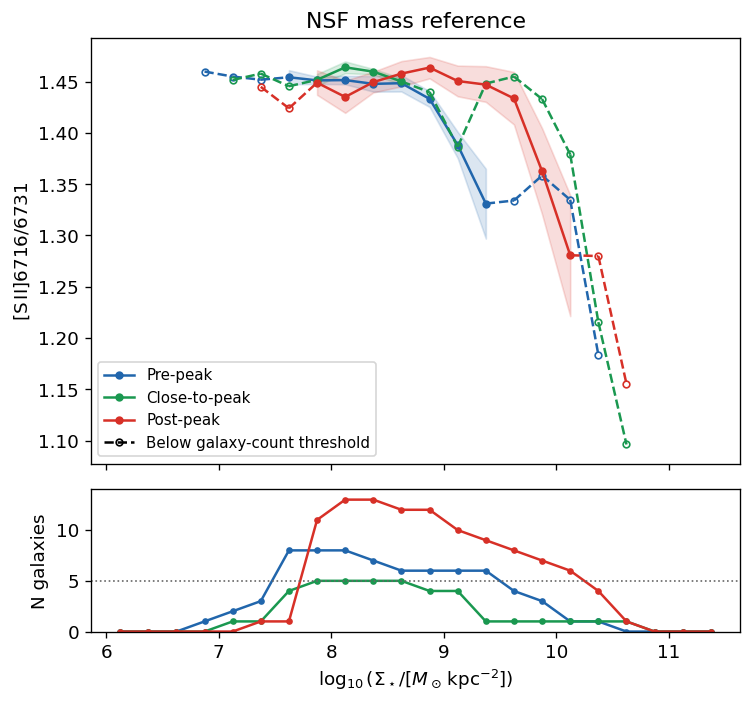

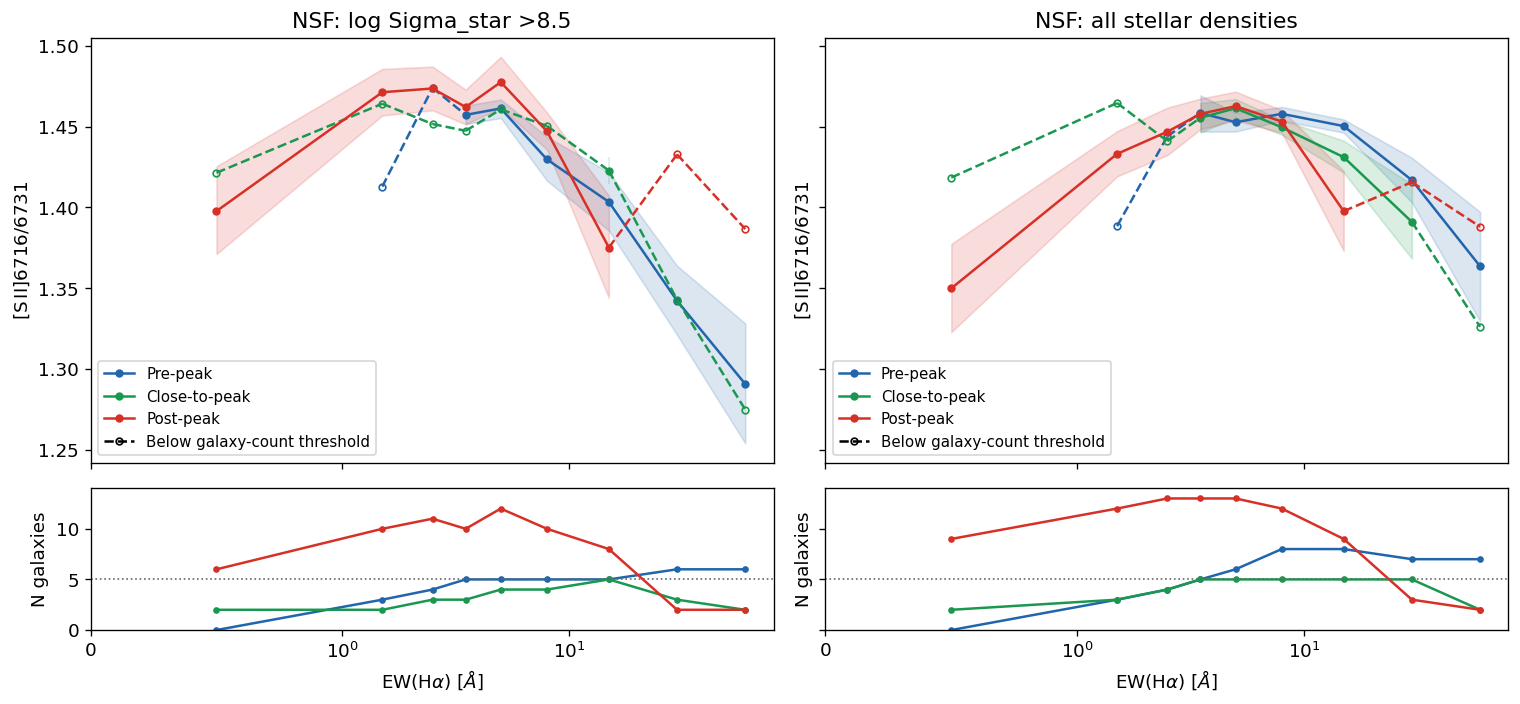

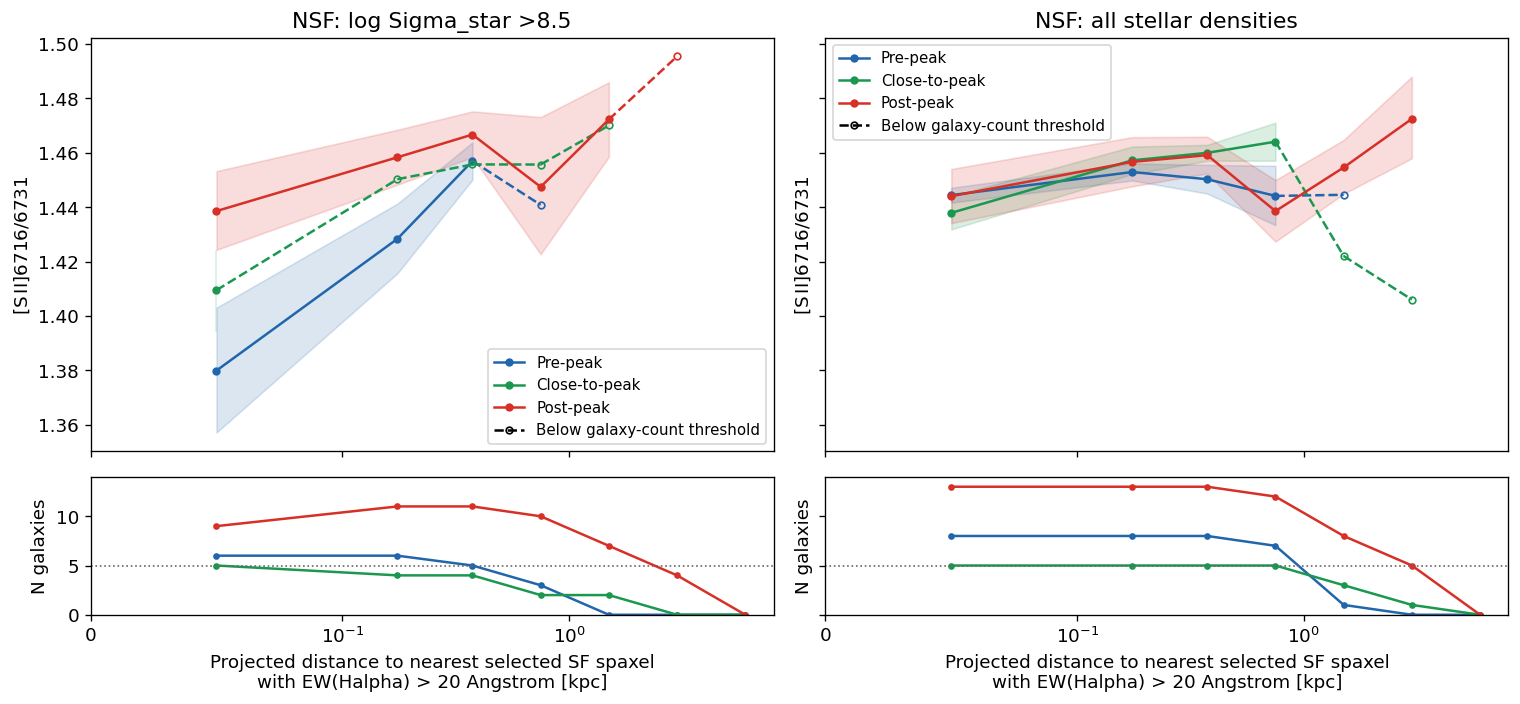

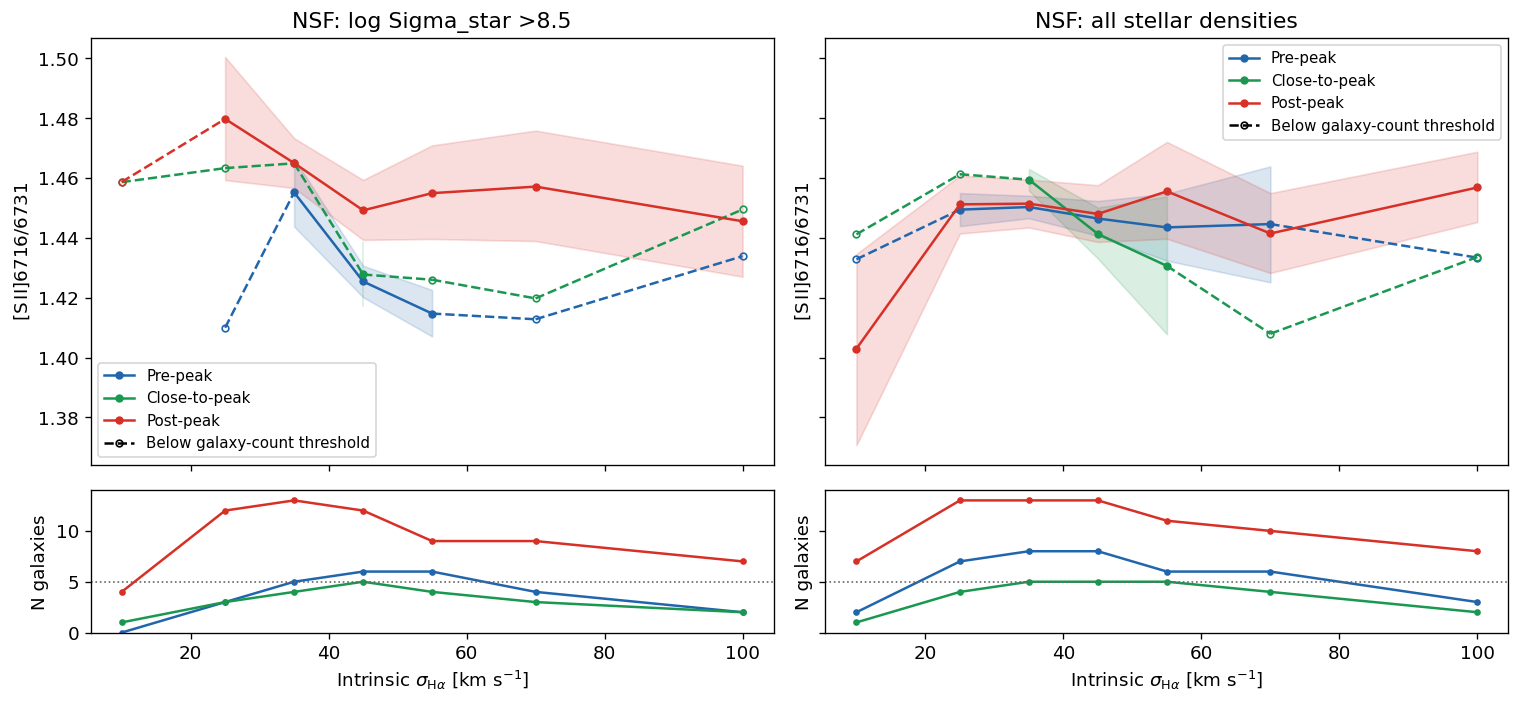

In [6]:
def plot_support_segments(ax, x, y, supported, color, label, ms=4):
    """Never bridge missing bins; any edge touching low-count data is dashed."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    supported = np.asarray(supported, bool)
    finite = np.isfinite(x) & np.isfinite(y)
    ax.plot([], [], color=color, marker='o', ms=ms, label=label)
    for j in range(len(x)-1):
        if finite[j] and finite[j+1]:
            style = '-' if supported[j] and supported[j+1] else '--'
            ax.plot(x[j:j+2], y[j:j+2], color=color, linestyle=style)
    for good, face in ((True, color), (False, 'none')):
        selected = finite & (supported == good)
        ax.plot(x[selected], y[selected], linestyle='none', marker='o', ms=ms,
                color=color, markerfacecolor=face)


XLABELS = {
    'log_sigma_star': r'$\log_{10}(\Sigma_\star/[M_\odot\,\mathrm{kpc}^{-2}])$',
    'ew_ha': r'EW(H$\alpha$) [$\AA$]',
    'distance_kpc': 'Projected distance to nearest selected SF spaxel\nwith EW(Halpha) > 20 Angstrom [kpc]',
    'sigma_intrinsic': r'Intrinsic $\sigma_{\mathrm{H}\alpha}$ [km s$^{-1}$]',
}
TITLES = {'mass_reference':'NSF mass reference', 'EW_high_mass':'NSF: log Sigma_star >8.5',
    'EW_all_mass':'NSF: all stellar densities', 'distance_high_mass':'NSF: log Sigma_star >8.5',
    'distance_all_mass':'NSF: all stellar densities', 'sigma_high_mass':'NSF: log Sigma_star >8.5',
    'sigma_all_mass':'NSF: all stellar densities'}
def plot_tests(tests):
    fig, axes = plt.subplots(2,len(tests), figsize=(6.4*len(tests),6), squeeze=False,
                             sharex='col', sharey='row', gridspec_kw={'height_ratios':[3,1]})
    for col,test in enumerate(tests):
        variable, edges, _ = TEST_SPECS[test]
        ax, count_ax = axes[:,col]
        for stage in STAGE_ORDER:
            sub = PROFILES.loc[PROFILES.test.eq(test)&PROFILES.stage.eq(stage)&np.isfinite(PROFILES.right)].sort_values('bin')
            x = (sub.left.to_numpy()+sub.right.to_numpy())/2
            y = sub.display_value.to_numpy()
            color = STAGE_COLORS[stage]
            plot_support_segments(ax, x, y, sub.supported.to_numpy(bool), color, STAGE_LABELS[stage])
            ax.fill_between(x,sub.low.to_numpy(),sub.high.to_numpy(),color=color,alpha=.16)
            count_ax.plot(x,sub.N_galaxies.to_numpy(),'o-',color=color,ms=3)
        count_ax.axhline(MIN_GALAXIES_PER_STAGE_BIN,color='.4',ls=':',lw=1)
        count_ax.set(ylabel='N galaxies',xlabel=XLABELS[variable],
                     ylim=(0,max(len(ids) for ids in STAGE_IDS.values())+1))
        if variable in ('ew_ha','distance_kpc'):
            count_ax.set_xscale('symlog',linthresh=1 if variable=='ew_ha' else .1)
            count_ax.set_xlim(0, edges[np.isfinite(edges)][-1])
        ax.set(title=TITLES[test],ylabel=r'$[\mathrm{S\,II}]6716/6731$')
        ax.plot([], [], 'k--', marker='o', markerfacecolor='none', ms=4,
                label='Below galaxy-count threshold')
        ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

plot_tests(['mass_reference'])
plot_tests(['EW_high_mass','EW_all_mass'])
plot_tests(['distance_high_mass','distance_all_mass'])
plot_tests(['sigma_high_mass','sigma_all_mass'])


## Numerical checks and interpretation boundary
The following checks verify accounting, the estimator, support rejection and sky-distance units. They do not validate a physical mechanism. Read the supported contrast tables and individual-galaxy medians before interpreting stage trends. PSF matching, spatially correlated flux errors, alternative signal-to-noise cuts, aperture/field coverage, AGN contamination, radius matching and the 7000-Angstrom fit-window check remain follow-up work.

In [7]:

toy = np.array([1.,3.,10.,np.nan])
toy_indices = np.array([[0,1,2,3],[0,0,1,3],[3,3,3,3]])
central, draws = bootstrap_mean_medians(toy,toy_indices)
sky_header = WCS(naxis=2)
sky_header.wcs.crpix=[1,1]
sky_header.wcs.cdelt=[-1/3600,1/3600]
sky_header.wcs.crval=[180,0]
sky_header.wcs.ctype=['RA---TAN','DEC--TAN']
sf_toy = np.array([[True,False]])
target_toy = ~sf_toy
d = nearest_sf_distance(sky_header.to_header(),sf_toy,target_toy,10.)[0,1]
checks = {
    'mean_of_medians': np.isclose(central,14/3),
    'whole_galaxy_duplicate_draw': np.isclose(draws[1],5/3),
    'all_missing_draw_nan': np.isnan(draws[2]),
    'distance_one_arcsec_at_10Mpc': np.isclose(d,10_000*np.deg2rad(1/3600),rtol=1e-6),
    'no_SF_distance_missing': np.isnan(nearest_sf_distance(sky_header.to_header(),sf_toy&False,target_toy,10.)).all(),
    'strict_high_mass': np.array_equal(mass_selection(np.array([8.5,8.5001]),'high'),[False,True]),
    'unique_galaxy_bins': not GALAXY_BINS.duplicated(['test','stage','GALID','bin']).any(),
    'ratio_subset_NSF': bool(RATIO_QC.N_ratio.le(RATIO_QC.N_NSF).all()),
    'rejected_estimates_missing': PROFILES.loc[~PROFILES.supported,['value','low','high']].isna().all().all(),
    'supported_stage_minimum': PROFILES.loc[PROFILES.supported,'N_galaxies'].ge(MIN_GALAXIES_PER_STAGE_BIN).all(),
    'paired_within_usable': GALAXY_BINS.N_paired.le(GALAXY_BINS.N_usable).all(),
}
for p in PROFILES.loc[PROFILES.supported].itertuples():
    g = GALAXY_BINS.query('test == @p.test and stage == @p.stage and bin == @p.bin and eligible')
    assert np.isclose(p.value,g['median'].mean())
checks['all_stage_estimates_match_galaxy_means'] = True

for p in PROFILES.loc[PROFILES.display_value.notna()].itertuples():
    g = GALAXY_BINS.query('test == @p.test and stage == @p.stage and bin == @p.bin and eligible')
    assert np.isclose(p.display_value, g['median'].mean())
checks['descriptive_values_match_available_galaxies'] = True

display(pd.Series(checks,name='passed'))
assert all(checks.values()), checks
display(GALAXY_BINS.drop(columns=['variable']))
print('SII_FOLLOWUP_CHECKS_OK')


SII_FOLLOWUP_CHECKS_OK


mean_of_medians                                True
whole_galaxy_duplicate_draw                    True
all_missing_draw_nan                           True
distance_one_arcsec_at_10Mpc                   True
no_SF_distance_missing                         True
strict_high_mass                               True
unique_galaxy_bins                             True
ratio_subset_NSF                               True
rejected_estimates_missing                     True
supported_stage_minimum                        True
paired_within_usable                           True
all_stage_estimates_match_galaxy_means         True
descriptive_values_match_available_galaxies    True
Name: passed, dtype: bool

,test,GALID,stage,bin,left,right,N_usable,N_paired,N_gas_bins,eligible,median
0,mass_reference,NGC4298,close-to-peak,0,6.00,6.25,0,0,0,False,NaN
1,mass_reference,NGC4298,close-to-peak,1,6.25,6.50,0,0,0,False,NaN
2,mass_reference,NGC4298,close-to-peak,2,6.50,6.75,0,0,0,False,NaN
3,mass_reference,NGC4298,close-to-peak,3,6.75,7.00,0,0,0,False,NaN
4,mass_reference,NGC4298,close-to-peak,4,7.00,7.25,2265,0,0,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2959,EW_joint_mass_3,NGC4567_8,pre-peak,5,6.00,10.00,11,11,11,False,1.246610
2960,EW_joint_mass_3,NGC4567_8,pre-peak,6,10.00,20.00,43,22,22,False,1.327201
2961,EW_joint_mass_3,NGC4567_8,pre-peak,7,20.00,40.00,1,1,1,False,1.460048
2962,EW_joint_mass_3,NGC4567_8,pre-peak,8,40.00,80.00,1,1,1,False,1.233620
